In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets
from torchvision.transforms import v2
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt

torch.manual_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Dispositivo activo: {device}")


Dispositivo activo: cuda


In [ ]:

# Transformación limpia: a Tensor y escalado [0.0, 1.0]
transform = v2.Compose([
    v2.ToImage(),
    v2.ToDtype(torch.float32, scale=True)
])

# Descarga y DataLoaders (usamos FashionMNIST como ejemplo)
train_dataset = datasets.MNIST(root='./data', train=True, download=True, transform=transform)
test_dataset = datasets.MNIST(root='./data', train=False, download=True, transform=transform)

#train_dataset = datasets.FashionMNIST(root='./data', train=True, download=True, transform=transform)
#test_dataset = datasets.FashionMNIST(root='./data', train=False, download=True, transform=transform)

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)

100%|██████████| 9.91M/9.91M [00:00<00:00, 18.5MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 510kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.67MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 2.88MB/s]


In [ ]:
class AutoencoderCNN(nn.Module):
    def __init__(self):
        super().__init__()

        # --- COMPONENTES DEL ENCODER ---
        # Reduce dimensiones espaciales y aumenta canales
        self.conv1 = nn.Conv2d(in_channels=1, out_channels=16, kernel_size=3, stride=2, padding=1) # N, 1, 28, 28 -> N, 16, 14, 14
        self.relu1 = nn.ReLU()

        self.conv2 = nn.Conv2d(in_channels=16, out_channels=32, kernel_size=3, stride=2, padding=1) # N, 16, 14, 14 -> N, 32, 7, 7
        self.relu2 = nn.ReLU()

        self.aplanar = nn.Flatten()
        self.fc_encoder = nn.Linear(in_features=32 * 7 * 7, out_features=64)

        # --- COMPONENTES DEL DECODER ---
        self.fc_decoder = nn.Linear(in_features=64, out_features=32 * 7 * 7)
        self.relu3 = nn.ReLU()

        self.desaplanar = nn.Unflatten(dim=1, unflattened_size=(32, 7, 7))

         # ConvTranspose2d hace la operación espacial i2nversa (upsampling)
        self.convT1 = nn.ConvTranspose2d(in_channels=32, out_channels=16, kernel_size=3, stride=2, padding=1, output_padding=1) #N, 32, 7, 7 -> N, 16, 14, 14
        self.relu4 = nn.ReLU()

        self.convT2 = nn.ConvTranspose2d(in_channels=16, out_channels=1, kernel_size=3, stride=2, padding=1, output_padding=1) #N, 16, 14, 14 -> N, 1, 28, 28
        # Usamos Sigmoid porque la salida debe escalar los píxeles al rango [0.0, 1.0]
        self.sigmoid = nn.Sigmoid()

    def encode(self, x):
        """Comprime la imagen de entrada en un vector latente determinista z."""
         # --- ENCODER (Fase de compresión) ---

        x = self.conv1(x)
        x = self.relu1(x)

        x = self.conv2(x)
        x = self.relu2(x)

        x = self.aplanar(x)
        z = self.fc_encoder(x)
        return z

    def decode(self, z):
        """Reconstruye la imagen original a partir del vector latente z."""
        # --- DECODER (Fase de reconstrucción) ---
        x = self.fc_decoder(z)
        x = self.relu3(x)

         # OPERACIÓN CRÍTICA: Restauramos la topología espacial para las convoluciones
        # x = x.view(-1, 32, 7, 7) # -1 infiere automáticamente el tamaño del batch
        x = self.desaplanar(x)

        x = self.convT1(x)
        x = self.relu4(x)

        x = self.convT2(x)
        x = self.sigmoid(x)
        return x

    def forward(self, x):
        """Flujo orquestado: imagen -> espacio latente -> imagen reconstruida."""
        z = self.encode(x)
        x_recon = self.decode(z)
        return x_recon

modelo_cnn = AutoencoderCNN().to(device)
print(modelo_cnn)

AutoencoderCNN(
  (conv1): Conv2d(1, 16, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
  (relu1): ReLU()
  (conv2): Conv2d(16, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
  (relu2): ReLU()
  (aplanar): Flatten(start_dim=1, end_dim=-1)
  (fc_encoder): Linear(in_features=1568, out_features=64, bias=True)
  (fc_decoder): Linear(in_features=64, out_features=1568, bias=True)
  (relu3): ReLU()
  (desaplanar): Unflatten(dim=1, unflattened_size=(32, 7, 7))
  (convT1): ConvTranspose2d(32, 16, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), output_padding=(1, 1))
  (relu4): ReLU()
  (convT2): ConvTranspose2d(16, 1, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), output_padding=(1, 1))
  (sigmoid): Sigmoid()
)


In [ ]:
# Usamos MSELoss para medir la diferencia de píxel a píxel
criterion = nn.MSELoss()
optimizer = optim.Adam(modelo_cnn.parameters(), lr=0.001)

epochs = 10
print("Iniciando entrenamiento del Autoencoder...\n")

for epoch in range(epochs):
    modelo_cnn.train()
    perdida_total = 0.0

    for images, _ in train_loader: # Ignoramos las labels (el _)
        images = images.to(device)

        optimizer.zero_grad()
        # Pasamos la imagen y obtenemos la reconstrucción
        reconstruccion = modelo_cnn(images)

        # La pérdida es la diferencia entre la imagen original y la reconstrucción
        loss = criterion(reconstruccion, images)
        loss.backward()
        optimizer.step()

        perdida_total += loss.item()

    perdida_media = perdida_total / len(train_loader)
    print(f"Epoch {epoch+1}/{epochs} | Loss de Reconstrucción (MSE): {perdida_media:.4f}")

Iniciando entrenamiento del Autoencoder...

Epoch 1/10 | Loss de Reconstrucción (MSE): 0.0274
Epoch 2/10 | Loss de Reconstrucción (MSE): 0.0059
Epoch 3/10 | Loss de Reconstrucción (MSE): 0.0042
Epoch 4/10 | Loss de Reconstrucción (MSE): 0.0035
Epoch 5/10 | Loss de Reconstrucción (MSE): 0.0031
Epoch 6/10 | Loss de Reconstrucción (MSE): 0.0029
Epoch 7/10 | Loss de Reconstrucción (MSE): 0.0027
Epoch 8/10 | Loss de Reconstrucción (MSE): 0.0026
Epoch 9/10 | Loss de Reconstrucción (MSE): 0.0025
Epoch 10/10 | Loss de Reconstrucción (MSE): 0.0024


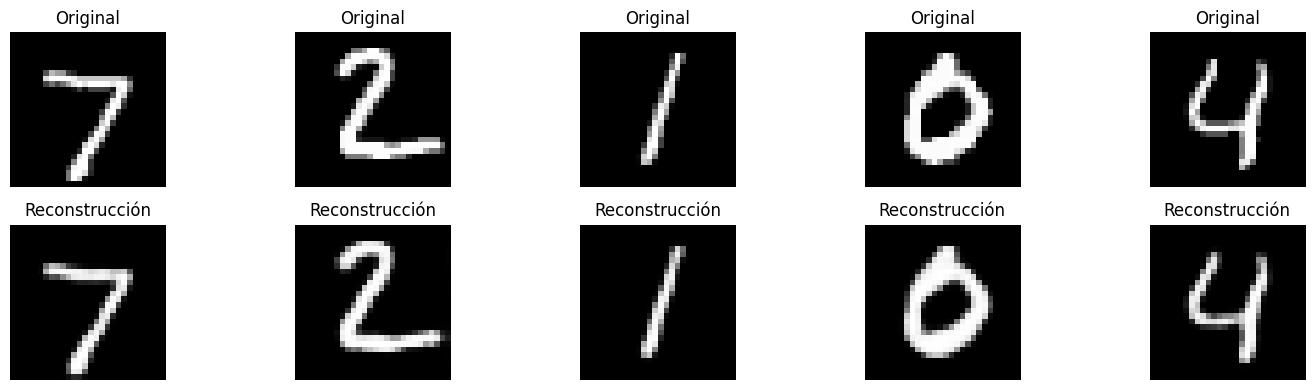

In [ ]:
def visualizar_reconstrucciones(modelo, dataloader, device, num_imagenes=10):
    modelo.eval()

    # Obtenemos un solo lote
    images, _ = next(iter(dataloader))
    images = images.to(device)

    with torch.no_grad():
        reconstrucciones = modelo(images)

    # Movemos a CPU para matplotlib
    images = images.cpu()
    reconstrucciones = reconstrucciones.cpu()

    fig, axes = plt.subplots(2, num_imagenes, figsize=(15, 4))

    for i in range(num_imagenes):
        # Fila superior: Originales
        axes[0, i].imshow(images[i].squeeze(), cmap='gray')
        axes[0, i].set_title("Original")
        axes[0, i].axis('off')

        # Fila inferior: Reconstrucciones
        axes[1, i].imshow(reconstrucciones[i].squeeze(), cmap='gray')
        axes[1, i].set_title("Reconstrucción")
        axes[1, i].axis('off')

    plt.tight_layout()
    plt.show()

visualizar_reconstrucciones(modelo_cnn, test_loader, device)